# Pearce-Hall Learning Model

The Pearce-Hall (PH) model is a reinforcement learning model that differs from the standard Rescorla-Wagner model by making the learning rate (associability) dynamic. The core idea is that an agent should learn more when they are uncertain about the outcome (high prediction error) and learn less when the outcome is well-predicted.

The model updates are defined as follows:

1.  **Value Update**:
    $$ V_{t+1} = V_t + \kappa \cdot \alpha_t \cdot (R_t - V_t) $$
    where $V$ is the value, $\kappa$ is a constant scaling factor, $\alpha$ is the associability (dynamic learning rate), and $R$ is the outcome.

2.  **Associability Update**:
    $$ \alpha_{t+1} = \gamma \cdot |R_t - V_t| + (1 - \gamma) \cdot \alpha_t $$
    where $\gamma$ controls how quickly the associability updates based on the current absolute prediction error.

This notebook demonstrates how the PH model adapts its learning rate in a changing environment.

In [2]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Import the Pearce-Hall update function
from behavioural_modelling.learning.pearce_hall import pearce_hall_update

# Set plotting style
sns.set_context("notebook")
sns.set_style("whitegrid")

## Simulated Task: Reversal Learning

We will simulate a simple task where an agent observes outcomes from a single option. 
1.  **Phase 1 (Trials 0-50)**: The option yields a reward 80% of the time.
2.  **Phase 2 (Trials 50-100)**: The option yields a reward 20% of the time (Reversal).

We expect the associability ($\alpha$) to decrease during the stable Phase 1 as the agent learns the value, and then spike at the beginning of Phase 2 when prediction errors suddenly increase.

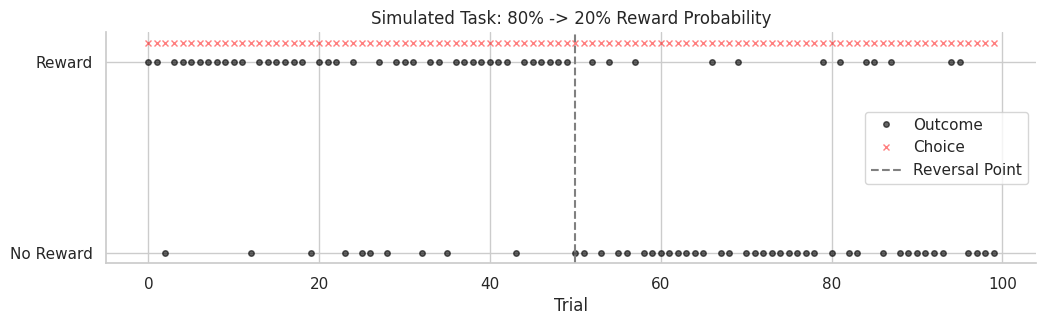

In [4]:
# Parameters
n_trials = 100
switch_point = 50
prob_phase1 = 0.8
prob_phase2 = 0.2
seed = 42

# Generate outcomes
key = jax.random.PRNGKey(seed)
k1, k2 = jax.random.split(key)
outcomes_p1 = jax.random.bernoulli(k1, p=prob_phase1, shape=(switch_point,)).astype(jnp.float32)
outcomes_p2 = jax.random.bernoulli(k2, p=prob_phase2, shape=(n_trials - switch_point,)).astype(jnp.float32)
outcomes = jnp.concatenate([outcomes_p1, outcomes_p2])

# Assuming the agent chooses the option on every trial for this demonstration
chosen = jnp.ones(n_trials)

# Visualization of the task structure
plt.figure(figsize=(12, 3))
plt.plot(outcomes, 'o', color='black', alpha=0.6, label='Outcome', markersize=4)
# Plot choices slightly offset so they are visible against rewards
plt.plot(chosen + 0.1, 'x', color='red', alpha=0.5, label='Choice', markersize=4)

plt.axvline(x=switch_point, color='gray', linestyle='--', label='Reversal Point')
plt.yticks([0, 1], ['No Reward', 'Reward'])
plt.xlabel('Trial')
plt.title(f'Simulated Task: {int(prob_phase1*100)}% -> {int(prob_phase2*100)}% Reward Probability')
plt.legend(loc='center right')
sns.despine()
plt.show()

## Running the Simulation

We define a scan function to run the model over the sequence of trials.

In [5]:
# Model Parameters
kappa = 0.5   # Scaling factor for value update
gamma = 0.5   # Decay rate for associability

# Initial State
v_init = 0.5
alpha_init = 0.5

def step_fn(state, inputs):
    v, alpha = state
    outcome, is_chosen = inputs
    
    # We wrap inputs in the tuple structure expected by pearce_hall_update
    outcome_chosen = (outcome, is_chosen)
    
    # Run update
    (v_new, alpha_new), (v_old, alpha_old, pe) = pearce_hall_update(
        v, alpha, outcome_chosen, kappa, gamma
    )
    
    # Return new state and values to record
    return (v_new, alpha_new), {
        "value": v_old, 
        "alpha": alpha_old, 
        "pe": pe,
        "abs_pe": jnp.abs(pe)
    }

# Run simulation using lax.scan
initial_state = (v_init, alpha_init)
scan_inputs = (outcomes, chosen)
_, history = jax.lax.scan(step_fn, initial_state, scan_inputs)

## Visualization

Let's plot the Value estimate and the Associability over time.

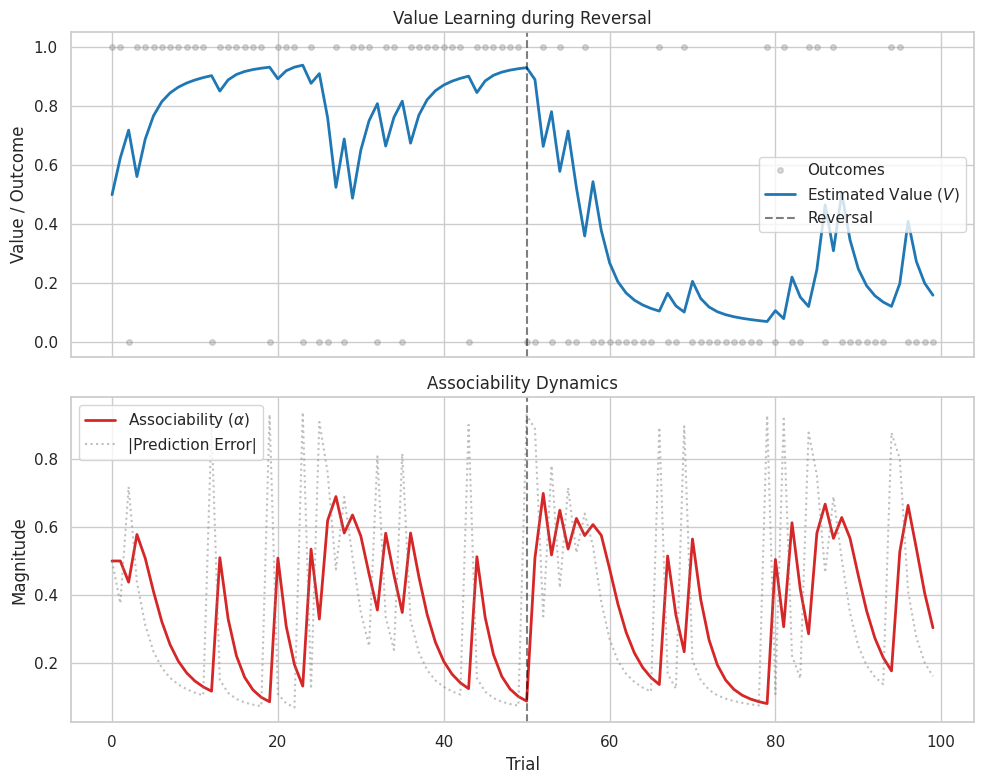

In [6]:
# Convert to numpy for plotting
metrics = {k: np.array(v) for k, v in history.items()}
trials = np.arange(n_trials)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Plot 1: Outcomes and Value Estimate
ax1.plot(trials, outcomes, 'o', color='gray', alpha=0.3, label='Outcomes', markersize=4)
ax1.plot(trials, metrics['value'], color='tab:blue', linewidth=2, label='Estimated Value ($V$)')
ax1.axvline(x=switch_point, color='k', linestyle='--', alpha=0.5, label='Reversal')
ax1.set_ylabel('Value / Outcome')
ax1.set_title('Value Learning during Reversal')
ax1.legend(loc='center right')

# Plot 2: Associability (Alpha) and Prediction Error magnitude
ax2.plot(trials, metrics['alpha'], color='tab:red', linewidth=2, label='Associability ($\\alpha$)')
ax2.plot(trials, metrics['abs_pe'], color='gray', linestyle=':', alpha=0.5, label='|Prediction Error|')
ax2.axvline(x=switch_point, color='k', linestyle='--', alpha=0.5)
ax2.set_xlabel('Trial')
ax2.set_ylabel('Magnitude')
ax2.set_title('Associability Dynamics')
ax2.legend()

plt.tight_layout()
plt.show()

### Interpretation

1.  **Phase 1 (0-50)**: Initially, prediction errors are high as the model learns the value (~0.8). Associability starts high but eventually settles to a lower level as the value stabilizes and prediction errors decrease (fluctuating only due to the stochastic rewards).
2.  **Reversal (50)**: When the probabilities switch, the agent experiences large prediction errors.
3.  **Phase 2 (50-100)**: The large prediction errors cause $\alpha$ to spike immediately. This increased learning rate allows the Value estimate to adjust rapidly to the new regime ($V \to 0.2$). Once the new value is learned, errors decrease, and $\alpha$ decays again.

This mechanism allows the Pearce-Hall model to automatically regulate its learning speed: being "fast" when the environment changes and "slow/stable" when the environment effectively predictable.

## Parameter Sensitivity Analysis

To better understand the model, let's explore how the two key parameters, $\kappa$ and $\gamma$, affect learning dynamics.

We'll define a helper function to quickly run simulations with different parameters.

In [7]:
def run_simulation(kappa_val, gamma_val):
    """Helper to run simulation with specific parameters."""
    def step_fn(state, inputs):
        v, alpha = state
        outcome, is_chosen = inputs
        outcome_chosen = (outcome, is_chosen)
        
        # Use simple wrapper to pass scalars into JIT-compiled function if needed
        # (Though JAX handles python scalars fine usually, explicit types help)
        (v_new, alpha_new), (v_old, alpha_old, pe) = pearce_hall_update(
            v, alpha, outcome_chosen, kappa_val, gamma_val
        )
        return (v_new, alpha_new), {"value": v_old, "alpha": alpha_old, "abs_pe": jnp.abs(pe)}
    
    # Run
    _, history = jax.lax.scan(step_fn, (0.5, 0.5), (outcomes, chosen))
    return history

### 1. Effect of $\kappa$ (Value Scaling Factor)

The parameter $\kappa$ scales the effect of the associability on the value update.
$$ V_{t+1} = V_t + \kappa \cdot \alpha_t \cdot (R_t - V_t) $$

*   **Low $\kappa$**: Updates are smaller even if associability is high. Learning is smoother but slower.
*   **High $\kappa$**: Updates are aggressive. The model reacts quickly but may oscillate or be noisy.

Here we fix $\gamma = 0.5$ and vary $\kappa$.

<>:10: SyntaxWarning: invalid escape sequence '\k'
<>:11: SyntaxWarning: invalid escape sequence '\k'
<>:23: SyntaxWarning: invalid escape sequence '\g'
<>:26: SyntaxWarning: invalid escape sequence '\k'
<>:10: SyntaxWarning: invalid escape sequence '\k'
<>:11: SyntaxWarning: invalid escape sequence '\k'
<>:23: SyntaxWarning: invalid escape sequence '\g'
<>:26: SyntaxWarning: invalid escape sequence '\k'
/tmp/ipykernel_113821/4202837314.py:10: SyntaxWarning: invalid escape sequence '\k'
  ax1.plot(metrics['value'], label=f'$\kappa={k}$')
/tmp/ipykernel_113821/4202837314.py:11: SyntaxWarning: invalid escape sequence '\k'
  ax2.plot(metrics['alpha'], label=f'$\kappa={k}$')
/tmp/ipykernel_113821/4202837314.py:23: SyntaxWarning: invalid escape sequence '\g'
  ax2.set_title(f'Associability ($\\alpha$)\nFixed $\gamma={fixed_gamma}$')
/tmp/ipykernel_113821/4202837314.py:26: SyntaxWarning: invalid escape sequence '\k'
  plt.suptitle('Effect of varying Kappa ($\kappa$)')


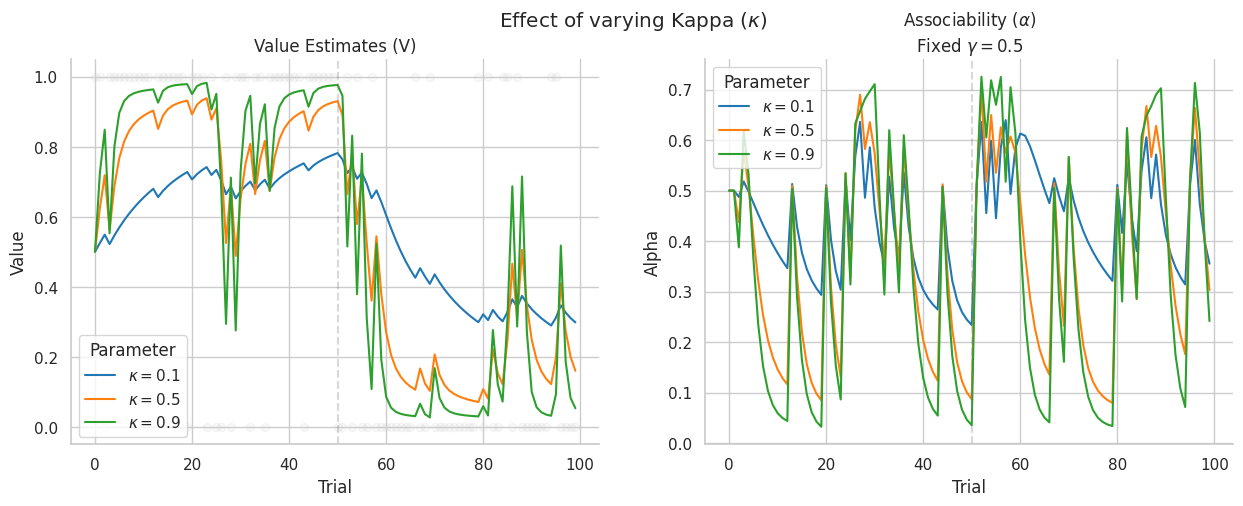

In [8]:
test_kappas = [0.1, 0.5, 0.9]
fixed_gamma = 0.5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

for k in test_kappas:
    hist = run_simulation(k, fixed_gamma)
    metrics = {k: np.array(v) for k, v in hist.items()}
    
    ax1.plot(metrics['value'], label=f'$\kappa={k}$')
    ax2.plot(metrics['alpha'], label=f'$\kappa={k}$')

# Styling
for ax in [ax1, ax2]:
    ax.axvline(x=switch_point, color='gray', linestyle='--', alpha=0.3)
    ax.set_xlabel('Trial')
    ax.legend(title='Parameter')

ax1.set_title('Value Estimates (V)')
ax1.set_ylabel('Value')
ax1.plot(outcomes, 'o', color='gray', alpha=0.05, zorder=-1) # Show outcomes faintly

ax2.set_title(f'Associability ($\\alpha$)\nFixed $\gamma={fixed_gamma}$')
ax2.set_ylabel('Alpha')

plt.suptitle('Effect of varying Kappa ($\kappa$)')
sns.despine()
plt.show()

### 2. Effect of $\gamma$ (Associability Decay Rate)

The parameter $\gamma$ determines how quickly the associability $\alpha$ updates in response to prediction errors. A higher $\gamma$ makes attention shift rapidly when outcomes are surprising (fast adaptation), whereas a lower $\gamma$ results in more stable, slowly evolving attention levels.

<>:10: SyntaxWarning: invalid escape sequence '\g'
<>:11: SyntaxWarning: invalid escape sequence '\g'
<>:19: SyntaxWarning: invalid escape sequence '\k'
<>:26: SyntaxWarning: invalid escape sequence '\g'
<>:10: SyntaxWarning: invalid escape sequence '\g'
<>:11: SyntaxWarning: invalid escape sequence '\g'
<>:19: SyntaxWarning: invalid escape sequence '\k'
<>:26: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_113821/104764986.py:10: SyntaxWarning: invalid escape sequence '\g'
  ax1.plot(metrics['value'], label=f'$\gamma={g}$')
/tmp/ipykernel_113821/104764986.py:11: SyntaxWarning: invalid escape sequence '\g'
  ax2.plot(metrics['alpha'], label=f'$\gamma={g}$')
/tmp/ipykernel_113821/104764986.py:19: SyntaxWarning: invalid escape sequence '\k'
  ax1.set_title(f'Value Estimates (V)\nFixed $\kappa={fixed_kappa}$')
/tmp/ipykernel_113821/104764986.py:26: SyntaxWarning: invalid escape sequence '\g'
  plt.suptitle('Effect of varying Gamma ($\gamma$)')


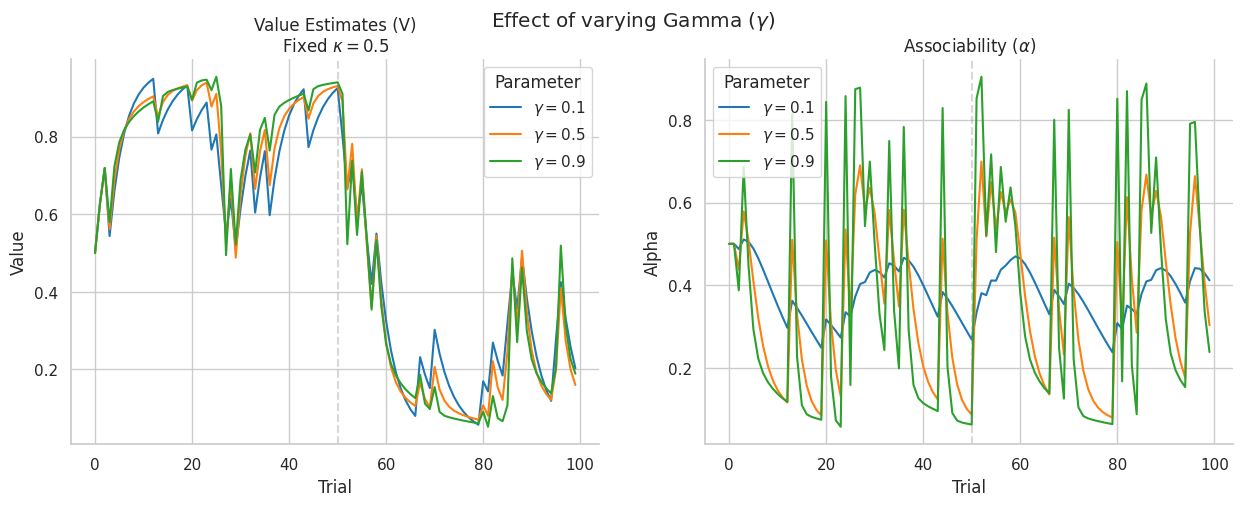

In [9]:
test_gammas = [0.1, 0.5, 0.9]
fixed_kappa = 0.5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

for g in test_gammas:
    hist = run_simulation(fixed_kappa, g)
    metrics = {k: np.array(v) for k, v in hist.items()}
    
    ax1.plot(metrics['value'], label=f'$\gamma={g}$')
    ax2.plot(metrics['alpha'], label=f'$\gamma={g}$')

# Styling
for ax in [ax1, ax2]:
    ax.axvline(x=switch_point, color='gray', linestyle='--', alpha=0.3)
    ax.set_xlabel('Trial')
    ax.legend(title='Parameter')

ax1.set_title(f'Value Estimates (V)\nFixed $\kappa={fixed_kappa}$')
ax1.set_ylabel('Value')
# ax1.plot(outcomes, 'o', color='gray', alpha=0.05, zorder=-1)

ax2.set_title('Associability ($\\alpha$)')
ax2.set_ylabel('Alpha')

plt.suptitle('Effect of varying Gamma ($\gamma$)')
sns.despine()
plt.show()